# The Zak transform: the mathematics from scratch, and the zero at (½, ½)

In `zak_sim` the Zak transform is a ready-made tool: take the DZT, build a pulsone, compute the channel. Here we **derive** it: what the operation is, where the "odd" quasi-periodicity comes from, why nothing is lost, and above all **why the Zak transform of any smooth, well-localized pulse must have a zero, and why for a symmetric pulse it sits exactly at the point $(\tfrac12,\tfrac12)$ of the unit cell**. That zero is where the Balian–Low theorem comes from, and it answers the question "why are the Gaussian symbols in Zak-OTFS not orthogonal" (sections 1 and 5 of `zak_sim`).

You only need Fourier series. Plan:
1. **The idea**: cut the signal tape into strips and run an FFT across the strips (the discrete case, one line of code).
2. **The definition** in continuous form and the meaning of $(\tau,\nu)$.
3. **Quasi-periodicity**: two derivations of two lines each; where the twist $e^{j2\pi\nu\tau}$ comes from.
4. **Inversion and Parseval's identity**: the Zak transform loses nothing and duplicates nothing.
5. **The link to Fourier** (the Poisson formula): Zak sits "between" time and frequency.
6. **An atlas of examples**: a δ-pulse, a tone, a rectangle, a Gaussian.
7. **The zero at $(\tfrac12,\tfrac12)$**: three explanations (an alternating sum, symmetry + twist, topology), how the zero moves, and why it is a vortex.
8. **Consequences**: an orthonormal lattice of pulses $\Leftrightarrow$ $\lvert Z\rvert\equiv1$, the Gram matrix, the Balian–Low theorem, the price of orthogonalization.
9. **The discrete version**: why an $M\times N$ grid with even $M,N$ hits the zero exactly.

**Convention.** In the mathematical sections we take $\tau_p=\nu_p=1$ (time in units of $\tau_p$, Doppler in units of $\nu_p=1/\tau_p$), as in `zak_sim`; the normalization factor $\sqrt{\tau_p}$ from there becomes 1. Every statement is checked numerically: theory is printed next to the measurement.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from scipy.optimize import minimize

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(1)

K_SUM = 40            # sum over k = −K…K; Gaussian tails e^{−πk²} are ≈ 0 beyond

## Primitives: the Zak transform (from time and from the spectrum), signals, a phase + modulus colouring

In [2]:
# ---------- continuous Zak transform (τp = νp = 1) ----------
def zak(x, tau, nu, K=K_SUM):
    """Z(τ,ν) = Σ_{k=−K..K} x(τ+k)·e^{−j2πνk} on the grid τ × ν (tau, nu are 1-D arrays); x is a function of time"""
    k = np.arange(-K, K + 1)
    xs = x(np.asarray(tau, float)[:, None] + k)                  # (Nτ, 2K+1): the comb of samples for each τ
    return xs @ np.exp(-2j * np.pi * np.outer(k, np.atleast_1d(nu)))

def zak_pairs(x, tau, nu, K=K_SUM):
    """the same, but for pairs of points (τ_i, ν_i): for paths and single points"""
    k = np.arange(-K, K + 1)
    tau = np.atleast_1d(np.asarray(tau, float)); nu = np.atleast_1d(np.asarray(nu, float))
    return (x(tau[:, None] + k) * np.exp(-2j * np.pi * nu[:, None] * k)).sum(1)

def zak_from_spectrum(X, tau, nu, K=K_SUM):
    """Z(τ,ν) = e^{j2πντ}·Σ_m X(ν+m)·e^{j2πmτ}: the same transform, computed from the spectrum X(f)"""
    m = np.arange(-K, K + 1)
    tau = np.asarray(tau, float); nu = np.atleast_1d(np.asarray(nu, float))
    return np.exp(2j * np.pi * np.outer(tau, nu)) * (X(nu[:, None] + m) @ np.exp(2j * np.pi * np.outer(m, tau))).T

# ---------- signals ----------
def gauss(t, a=1.0):  return np.exp(-np.pi * (t / a) ** 2)          # at a = 1 the Gaussian equals its own spectrum
def rect(t):          return ((t >= 0) & (t < 1)).astype(float)       # a rectangle on [0,1)
def sinc_t(t):        return np.sinc(t)                                # sin(πt)/(πt)

def random_signal(rng, n=5):
    """a smooth generic signal: a sum of shifted, modulated Gaussians"""
    c = rng.uniform(-1, 1, n); w = rng.uniform(0.6, 1.2, n); f = rng.uniform(-1, 1, n)
    amp = rng.standard_normal(n) + 1j * rng.standard_normal(n)
    return lambda t: sum(amp[i] * gauss(np.asarray(t) - c[i], w[i]) * np.exp(2j * np.pi * f[i] * np.asarray(t)) for i in range(n))

def phase_rgb(Z, vmax=None):
    """hue = phase, brightness = modulus"""
    A = np.abs(Z); vmax = vmax or A.max()
    h = (np.angle(Z) / (2 * np.pi)) % 1
    return hsv_to_rgb(np.stack([h, np.ones_like(h), np.clip(A / vmax, 0, 1)], -1))

def show_dd(ax, Z, ext, title, vmax=None, phase=False):
    """Z[iτ, iν] → an image with τ horizontal, ν vertical"""
    img = phase_rgb(Z.T, vmax) if phase else np.abs(Z.T)
    im = ax.imshow(img, origin="lower", extent=ext, aspect="equal", cmap=None if phase else "viridis", vmin=0 if not phase else None)
    ax.set_xlabel("τ / τp"); ax.set_ylabel("ν / νp"); ax.set_title(title, fontsize=10); ax.grid(False)
    return im

## 1. The idea: a tape cut into strips
Take a signal of $MN$ samples, **cut it into $N$ blocks of $M$ samples** and stack the blocks: this gives a matrix $A[n,k]=x[k+nM]$, where $k=0\dots M-1$ is the position inside a block ("fast time", delay) and $n=0\dots N-1$ is the block number ("slow time"). Now do an **FFT along $n$ in each column**:
$$Z[k,l]=\frac1{\sqrt N}\sum_{n=0}^{N-1}x[k+nM]\,e^{-j2\pi nl/N}.$$
This is the discrete Zak transform (DZT). There is nothing more to it: **reshape + FFT**.

Why $k$ is delay and $l$ is Doppler. A delay of $d$ samples shifts the picture along $k$. A Doppler shift $\nu$ multiplies the signal by $e^{j2\pi\nu t}$; in neighbouring blocks (a period $\tau_p=M/B$ apart) the same position $k$ picks up a factor $e^{j2\pi\nu\tau_p}$, so along $n$ the signal rotates at frequency $\nu\tau_p$. That is exactly what the FFT over $n$ finds: a peak at $l=N\nu/\nu_p$. So the 2-D picture $Z[k,l]$ reads "where inside the period" × "how fast that place changes from period to period".

Below: a tape of 12 samples, $M=4$, $N=3$. The FFT matches the term-by-term sum to machine precision.

tape x  = [3 1 4 1 5 9 2 6 5 3 5 8]
after reshape (row = block, column = delay k):
 [[3 1 4 1]
 [5 9 2 6]
 [5 3 5 8]]
max |FFT − definition| = 4.0e-15


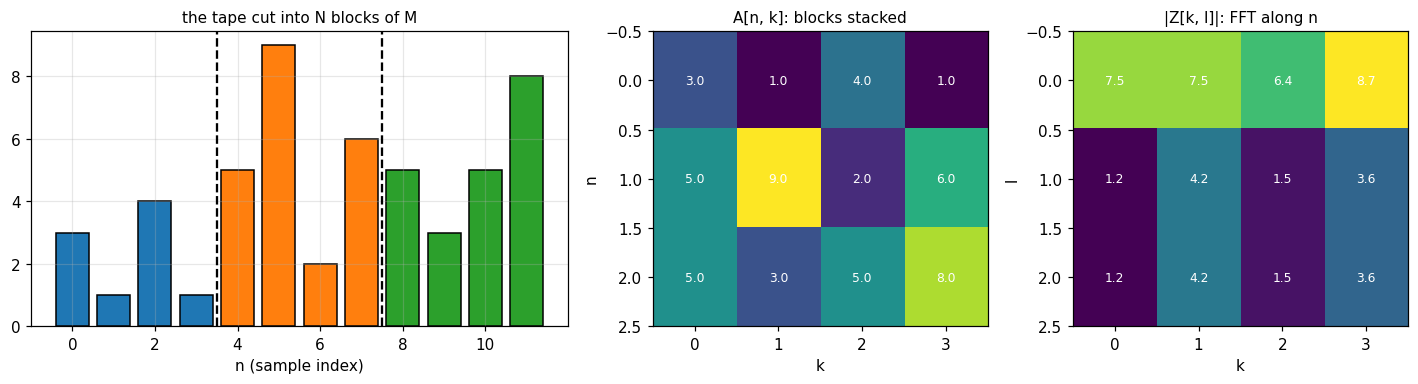

In [3]:
M, N = 4, 3                                       # 4 delay samples per block × 3 blocks
x = np.array([3, 1, 4, 1, 5, 9, 2, 6, 5, 3, 5, 8], complex)    # a tape of MN = 12 samples
A = x.reshape(N, M)                               # row n is block n: A[n, k] = x[k + nM]
Z_fft = (np.fft.fft(A, axis=0) / np.sqrt(N)).T    # Z[k, l]: FFT over the block index n
Z_sum = np.array([[sum(x[k + n * M] * np.exp(-2j * np.pi * n * l / N) for n in range(N)) / np.sqrt(N)
                   for l in range(N)] for k in range(M)])        # the definition, term by term
print("tape x  =", x.real.astype(int))
print("after reshape (row = block, column = delay k):\n", A.real.astype(int))
print(f"max |FFT − definition| = {np.max(np.abs(Z_fft - Z_sum)):.1e}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
ax[0].bar(np.arange(M * N), x.real, color=[f"C{i // M}" for i in range(M * N)], edgecolor="k")
for n in range(1, N): ax[0].axvline(n * M - 0.5, color="k", ls="--")
ax[0].set_xlabel("n (sample index)"); ax[0].set_title("the tape cut into N blocks of M", fontsize=10)
for a, img, ttl in ((ax[1], A.real, "A[n, k]: blocks stacked"), (ax[2], np.abs(Z_fft.T), "|Z[k, l]|: FFT along n")):
    a.imshow(img, cmap="viridis", aspect="auto"); a.grid(False); a.set_title(ttl, fontsize=10)
    for (i, j), v in np.ndenumerate(img): a.text(j, i, f"{v:.1f}", ha="center", va="center", color="w", fontsize=8)
ax[1].set_xlabel("k"); ax[1].set_ylabel("n"); ax[2].set_xlabel("k"); ax[2].set_ylabel("l")
plt.tight_layout(); plt.show()

## 2. The continuous definition
Let $x(t)$ be a signal on the whole axis and the period $\tau_p=1$. Fix a **shift inside the period** $\tau$ and take the "comb" of samples $\{x(\tau+k)\}_{k\in\mathbb Z}$, the values of the signal at $\tau,\ \tau\pm1,\ \tau\pm2,\dots$. This is a sequence in $k$, and its Fourier series in the "frequency" $\nu$ is the Zak transform:
$$\boxed{\,Z_x(\tau,\nu)=\sum_{k\in\mathbb Z}x(\tau+k)\,e^{-j2\pi\nu k}\,}$$
Read it as: **$\tau$ is "where in the period we look"; $\nu$ is "how fast the value at that place changes from period to period"**. Two extreme examples: if $x$ is a δ-pulse, the comb is empty or a single point for every $\nu$, and $\lvert Z\rvert$ does not depend on $\nu$; if $x=e^{j2\pi f t}$ is a pure tone, the value is simply multiplied by $e^{j2\pi f}$ from period to period, and all the energy sits at one $\nu=f \bmod 1$.

Left: a Gaussian and two combs (for $\tau=0.2$ and $\tau=0.5$). Right: $\lvert Z(\tau,\nu)\rvert$ as a function of $\nu$ for those two $\tau$. Look at the red curve ($\tau=0.5$): it touches zero at $\nu=0.5$. That zero is what this notebook is about.

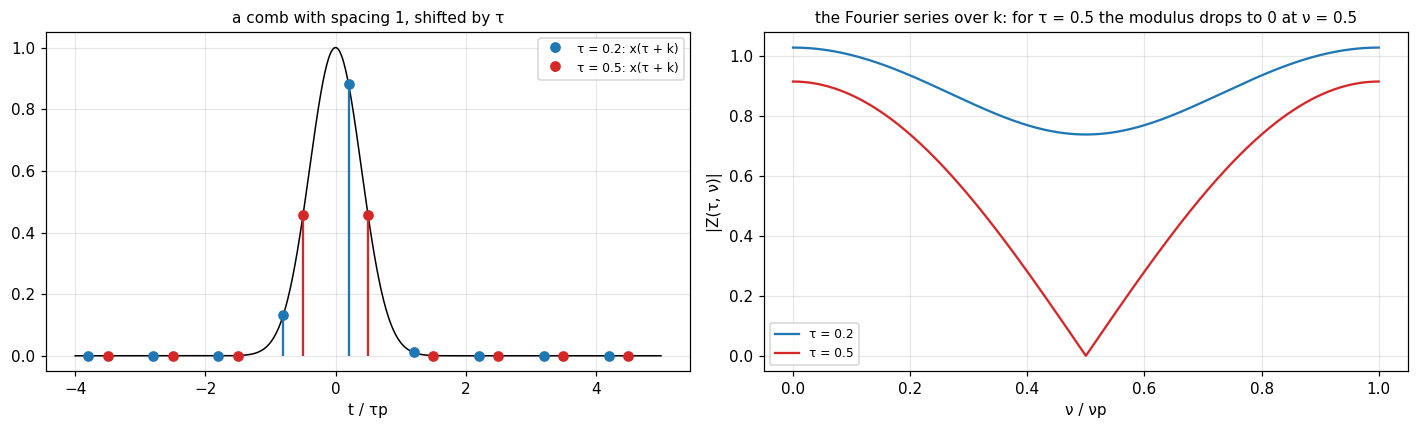

|Z(0.2, 0.5)| = 0.7372      |Z(0.5, 0.5)| = 5.55e-17


In [4]:
g = gauss
t = np.linspace(-4, 5, 1000)
nu = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(t, g(t), "k", lw=1)
for tau0, c in ((0.2, "C0"), (0.5, "C3")):
    ks = np.arange(-4, 5)
    ax[0].stem(tau0 + ks, g(tau0 + ks), linefmt=c + "-", markerfmt=c + "o", basefmt=" ", label=f"τ = {tau0}: x(τ + k)")
    ax[1].plot(nu, np.abs(zak(g, [tau0], nu)[0]), c, label=f"τ = {tau0}")
ax[0].set_xlabel("t / τp"); ax[0].legend(fontsize=8); ax[0].set_title("a comb with spacing 1, shifted by τ", fontsize=10)
ax[1].set_xlabel("ν / νp"); ax[1].set_ylabel("|Z(τ, ν)|"); ax[1].legend(fontsize=8)
ax[1].set_title("the Fourier series over k: for τ = 0.5 the modulus drops to 0 at ν = 0.5", fontsize=10)
plt.tight_layout(); plt.show()
print(f"|Z(0.2, 0.5)| = {abs(zak_pairs(g, 0.2, 0.5)[0]):.4f}      |Z(0.5, 0.5)| = {abs(zak_pairs(g, 0.5, 0.5)[0]):.2e}")

## 3. Quasi-periodicity: where the twist comes from
**In $\nu$.** $e^{-j2\pi(\nu+1)k}=e^{-j2\pi\nu k}$ for integer $k$, so $Z(\tau,\nu+1)=Z(\tau,\nu)$: a clean period of 1.

**In $\tau$.** Shift $\tau$ by 1 and relabel $m=k+1$:
$$Z(\tau+1,\nu)=\sum_k x(\tau+k+1)e^{-j2\pi\nu k}=\sum_m x(\tau+m)\,e^{-j2\pi\nu(m-1)}=e^{\,j2\pi\nu}\,Z(\tau,\nu).$$
A shift by one period in delay does not return the function; it **multiplies it by a phase that depends on $\nu$**. In general
$$\boxed{Z(\tau+n,\nu+m)=e^{\,j2\pi n\nu}\,Z(\tau,\nu)\qquad n,m\in\mathbb Z}$$
This is the "quasi-periodicity" from `zak_sim`. Its consequences:
- **the modulus $\lvert Z\rvert$ is periodic along both axes**, and all the phase non-periodicity is collected in the factor $e^{j2\pi n\nu}$;
- it suffices to know $Z$ on the **unit square** $[0,1)^2$; the rest of the plane follows;
- the phase is "twisted": a shift of $\tau$ by 1 multiplies the value by $e^{j2\pi\nu}$: at $\nu=\tfrac12$ that is $-1$ (half a turn), at $\nu=1$ a full turn. This is not an accident: it is the same non-commutativity of delay and Doppler that produces the twisted convolution in the channel: $T_\tau D_\nu=e^{-j2\pi\nu\tau}D_\nu T_\tau$.

Below: a check on a generic signal (complex, asymmetric) at 2000 random points, and a picture of the Gaussian over nine cells: modulus on the left (it repeats), phase on the right (the colour winds along $\tau$).

max|Z(τ+1,ν) − e^(j2πν)·Z(τ,ν)| = 7.7e-15      max|Z(τ,ν+1) − Z(τ,ν)| = 1.4e-14      max|Z(τ−3,ν) − e^(−j2π·3ν)·Z(τ,ν)| = 2.4e-14


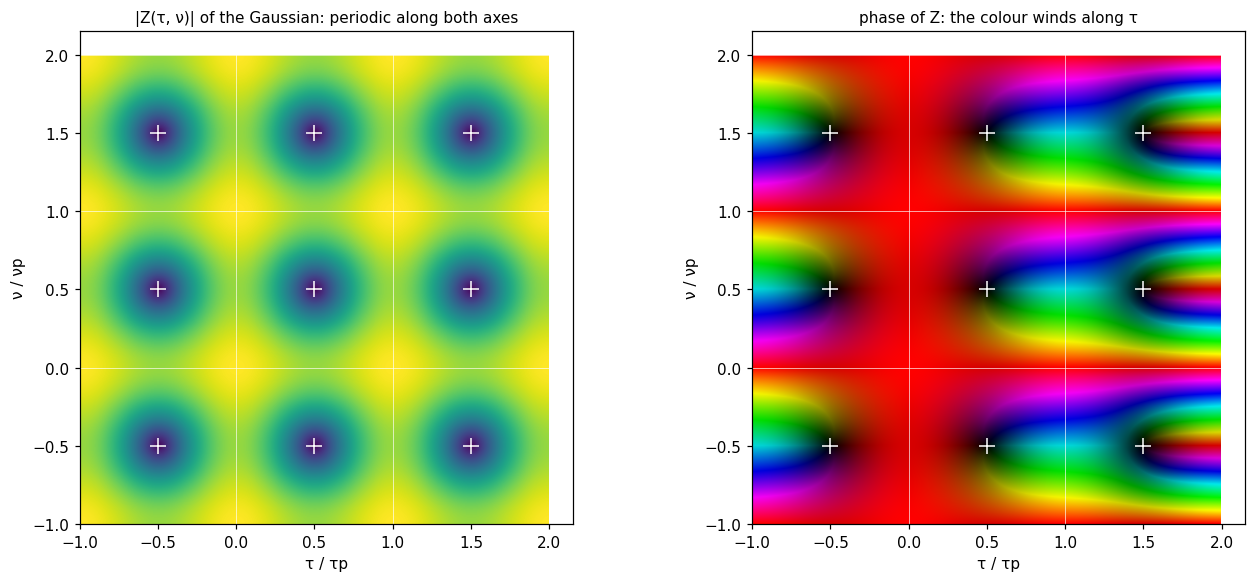

In [5]:
xr = random_signal(rng)                                         # a generic signal (not even, not real)
P = rng.uniform(-2, 2, (2000, 2)); tt, nn = P[:, 0], P[:, 1]
Z0 = zak_pairs(xr, tt, nn)
e_tau = np.max(np.abs(zak_pairs(xr, tt + 1, nn) - np.exp(2j * np.pi * nn) * Z0))
e_nu = np.max(np.abs(zak_pairs(xr, tt, nn + 1) - Z0))
e_tau3 = np.max(np.abs(zak_pairs(xr, tt - 3, nn) - np.exp(-2j * np.pi * 3 * nn) * Z0))
print(f"max|Z(τ+1,ν) − e^(j2πν)·Z(τ,ν)| = {e_tau:.1e}      max|Z(τ,ν+1) − Z(τ,ν)| = {e_nu:.1e}      max|Z(τ−3,ν) − e^(−j2π·3ν)·Z(τ,ν)| = {e_tau3:.1e}")

tau = np.arange(-150, 300) / 150; nu = np.arange(-150, 300) / 150
Zg = zak(g, tau, nu)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.4))
ext = (tau[0], tau[-1], nu[0], nu[-1])
show_dd(ax[0], Zg, ext, "|Z(τ, ν)| of the Gaussian: periodic along both axes")
show_dd(ax[1], Zg, ext, "phase of Z: the colour winds along τ", phase=True)
for a in ax:
    for u in range(-1, 3): a.axvline(u, color="w", lw=0.6, alpha=0.7); a.axhline(u, color="w", lw=0.6, alpha=0.7)
    a.plot([0.5 + i for i in range(-1, 2)] * 3, [0.5 + j for j in range(-1, 2) for _ in range(3)], "w+", ms=10)
plt.tight_layout(); plt.show()

## 4. Inversion and Parseval's identity
Since $Z(\tau,\cdot)$ is the Fourier series of the sequence $x(\tau+k)$, its coefficients are integrals over one period $\nu\in[0,1)$. For $k=0$:
$$\boxed{x(t)=\int_0^1 Z(t,\nu)\,d\nu}\qquad\text{(because }\textstyle\int_0^1e^{-j2\pi\nu k}d\nu=\delta_{k0}).$$
For the energy, cut the axis into cells $[n,n+1)$ and apply Parseval for Fourier series at each $\tau$:
$$\int_{-\infty}^{\infty}\lvert x(t)\rvert^2dt=\int_0^1\sum_k\lvert x(\tau+k)\rvert^2d\tau=\int_0^1\!\!\int_0^1\lvert Z(\tau,\nu)\rvert^2\,d\nu\,d\tau.$$
Result: **$x\mapsto Z_x$ is a unitary map** $L^2(\mathbb R)\to L^2([0,1)^2)$. No information is lost (an inverse exists) and none is duplicated (energy is conserved). That is why the "Zak plane" is an honest replacement for the time axis, not one more redundant representation like a spectrogram.

In [6]:
nu_g = np.arange(64) / 64
t0 = rng.uniform(-3, 3, 6)
x_rec = zak(xr, t0, nu_g).mean(axis=1)                          # ∫₀¹ Z(t, ν) dν
print(f"reconstruction x(t) = ∫₀¹ Z(t,ν)dν, six random t: max|error| = {np.max(np.abs(x_rec - xr(t0))):.1e}")

dt = 0.005; tg = np.arange(-15, 15, dt)
E_time = np.sum(np.abs(xr(tg)) ** 2) * dt                       # ∫|x(t)|² dt
Zq = zak(xr, np.arange(200) / 200, np.arange(64) / 64)
E_zak = np.mean(np.abs(Zq) ** 2)                                # ∬ over the unit cell
print(f"∫|x|²dt = {E_time:.6f}      ∬_[0,1)² |Z|² dτdν = {E_zak:.6f}      rel. diff = {abs(E_time - E_zak) / E_time:.1e}")

reconstruction x(t) = ∫₀¹ Z(t,ν)dν, six random t: max|error| = 1.6e-16
∫|x|²dt = 3.609163      ∬_[0,1)² |Z|² dτdν = 3.609163      rel. diff = 1.6e-13


## 5. The link to Fourier: Zak sits "between" time and frequency
Apply the Poisson formula $\sum_k f(k)=\sum_m\hat f(m)$ to the sum over $k$ with $f(s)=x(\tau+s)e^{-j2\pi\nu s}$. The Fourier transform of such an $f$ is $e^{j2\pi(\nu+m)\tau}X(\nu+m)$, so
$$\boxed{Z_x(\tau,\nu)=e^{\,j2\pi\nu\tau}\sum_{m\in\mathbb Z}X(\nu+m)\,e^{\,j2\pi m\tau}}$$
This is **the same transform, but computed from samples of the spectrum** $X(f)$ at $\nu,\ \nu\pm1,\dots$ (a comb in frequency). The roles are symmetric: a comb in time + a Fourier series in $\nu$ $\Leftrightarrow$ a comb in frequency + a Fourier series in $\tau$. So the $(\tau,\nu)$ plane is neither "closer to time" nor "closer to frequency": it is a common intermediate language in which both the signal and its spectrum look alike. One practical consequence: for a filter whose spectrum is localized rather than its pulse (sinc), the formula can be used directly.

A check on a Gaussian of width $a=0.7$, $X(f)=a\,e^{-\pi a^2f^2}$.

In [7]:
a = 0.7
ga  = lambda t: gauss(t, a)
Ga  = lambda f: a * np.exp(-np.pi * (a * f) ** 2)                # Fourier transform of the Gaussian
tt = rng.uniform(-1, 1, 5); nn = rng.uniform(-1, 1, 5)
Z_time = zak_pairs(ga, tt, nn)
Z_freq = np.array([zak_from_spectrum(Ga, [u], [v])[0, 0] for u, v in zip(tt, nn)])
print("Z from time samples :", np.round(Z_time, 6))
print("Z from spectrum samples:", np.round(Z_freq, 6))
print(f"max|Δ| = {np.max(np.abs(Z_time - Z_freq)):.1e}")

Z from time samples : [-0.232789-2.38254e-01j  0.862148-1.16778e-01j  1.000241+5.04000e-04j
  0.753863-5.21082e-01j -0.437814-2.59442e-01j]
Z from spectrum samples: [-0.232789-2.38254e-01j  0.862148-1.16778e-01j  1.000241+5.04000e-04j
  0.753863-5.21082e-01j -0.437814-2.59442e-01j]
max|Δ| = 2.5e-16


## 6. An atlas of examples
Let us look at $\lvert Z\rvert$ on the unit square for four signals:
- **almost a δ-pulse** (a narrow Gaussian): energy in a narrow strip in $\tau$ across all $\nu$: localized in delay, smeared in Doppler;
- **almost a tone** (a very wide Gaussian): the other way around, a narrow strip in $\nu$ across all $\tau$;
- **Gaussian, $a=1$**: localized on both axes, a "spot"; at $a=1$ it equals its own spectrum, and the picture is symmetric under $\tau\leftrightarrow\nu$;
- **rectangle $[0,1)$**: on $[0,1)$ exactly one sample ($k=0$) lands in the comb, so $Z\equiv1$ and $\lvert Z\rvert\equiv1$ **everywhere**, with no zero at all. But this $Z$ is *discontinuous*: at the border $\tau=1$ it "jumps" $1\to e^{j2\pi\nu}$. (In the pictures the δ-pulse sits at $\tau=0\equiv1$, hence the strips at the left and right edges.)

The table under the figure is the minimum and maximum of $\lvert Z\rvert$. For every smooth signal the minimum is zero (to machine precision, since the grid contains the point $(0.5,0.5)$); for the rectangle it is one. We come back to this contrast in sections 7–8.

signal                                          min|Z|    max|Z|
almost a δ-pulse (a = 0.08)                   6.20e-70  1.00e+00
Gaussian, a = 1                               6.01e-17  1.09e+00
rectangle [0,1)                               1.00e+00  1.00e+00
almost a tone (a = 12)                        5.36e-18  1.20e+01


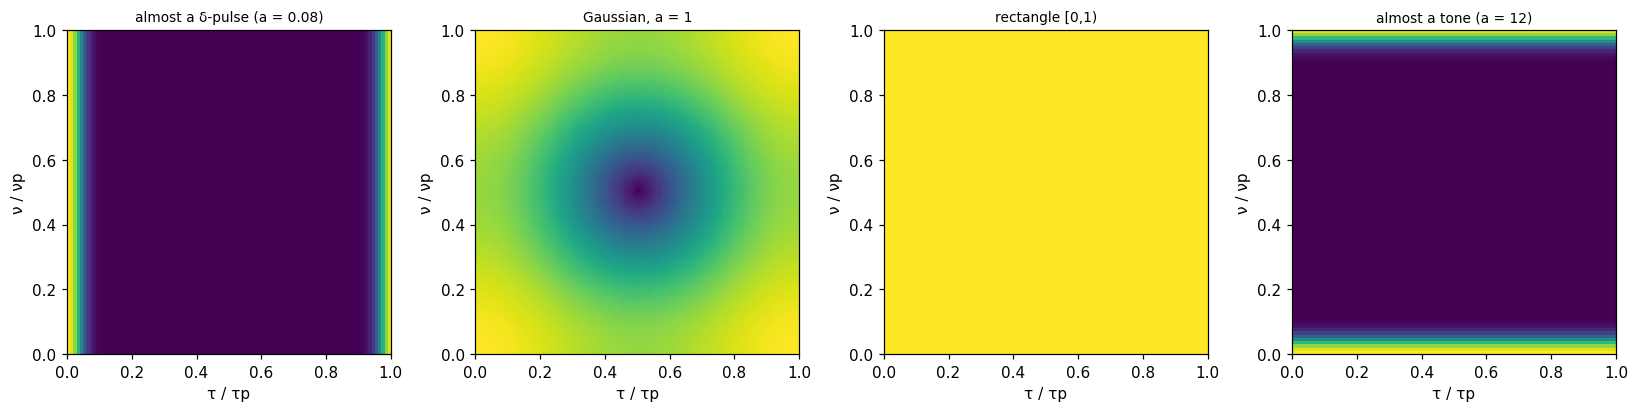

In [8]:
tau = np.arange(100) / 100; nu = np.arange(100) / 100            # the grid contains the point 0.5
cases = [("almost a δ-pulse (a = 0.08)", lambda t: gauss(t, 0.08), 40),
         ("Gaussian, a = 1", gauss, 40),
         ("rectangle [0,1)", rect, 40),
         ("almost a tone (a = 12)", lambda t: gauss(t, 12), 120)]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.9))
print(f"{'signal':<44}{'min|Z|':>10}{'max|Z|':>10}")
for a_, (name, f, K) in zip(ax, cases):
    Zc = zak(f, tau, nu, K=K)
    im = show_dd(a_, Zc, (0, 1, 0, 1), name)
    a_.title.set_fontsize(9)
    print(f"{name:<44}{np.abs(Zc).min():>10.2e}{np.abs(Zc).max():>10.2e}")
plt.tight_layout(); plt.show()

## 7. The zero at $(\tfrac12,\tfrac12)$
**Claim A (symmetry).** If the pulse is **even**, $x(-t)=x(t)$, then $Z_x(\tfrac12,\tfrac12)=0$.

**Claim B (general).** If $x$ is continuous and decays faster than $1/\lvert t\rvert^{1+\varepsilon}$ (so the series for $Z$ converges uniformly and $Z$ is a continuous function), then $Z_x$ **has a zero in every cell**. Where exactly depends on the signal; for an even one it is at $(\tfrac12,\tfrac12)$.

Three independent explanations follow, from the simplest to the most general.

### 7a. An alternating sum: the terms cancel in pairs
Put $\tau=\nu=\tfrac12$ into the definition: $e^{-j\pi k}=(-1)^k$, and
$$Z(\tfrac12,\tfrac12)=\sum_k(-1)^k\,x(\tfrac12+k)=\dots-x(-\tfrac32)+x(-\tfrac12)\;-\;x(\tfrac12)+x(\tfrac32)-\dots$$
For an even $x$ the values are symmetric: $x(\tfrac12+k)=x(-\tfrac12-k)$. Pair the term $k$ with the term $k'=-1-k$: their moduli are equal, while the signs $(-1)^k$ and $(-1)^{-1-k}=-(-1)^k$ are **opposite**. The whole sum splits into pairs of the form $a-a=0$. That is the zero, with no assumption about the pulse shape: Gaussian, raised cosine, any even function. Below are the table of terms (a wider Gaussian, $a=2$, is used so that more terms are visible) and bars: the terms $k$ and $-1-k$ of one colour have equal modulus and opposite sign.

What if the pulse is shifted by $a$ in time and modulated by $b$ in frequency, $x_s(t)=x(t-a)e^{j2\pi bt}$? A direct calculation gives $Z_{x_s}(\tau,\nu)=e^{j2\pi b\tau}Z_x(\tau-a,\nu-b)$, so **the whole landscape moves** and the zero relocates to $(\tfrac12+a,\ \tfrac12+b)$. The right plot checks this numerically with $a=0.2$, $b=0.1$.

  k  t = ½ + k      x(t)  (−1)^k        term
 -4       -3.5   0.00007       1     0.00007
 -3       -2.5   0.00738      -1    -0.00738
 -2       -1.5   0.17082       1     0.17082
 -1       -0.5   0.82172      -1    -0.82172
  0        0.5   0.82172       1     0.82172
  1        1.5   0.17082      -1    -0.17082
  2        2.5   0.00738       1     0.00738
  3        3.5   0.00007      -1    -0.00007
sum = Z(½, ½) = 0.00e+00
|Z(½,½)| for the shifted signal = 0.589
zero found at (τ, ν) = (0.700000, 0.600000),  prediction (½ + a, ½ + b) = (0.700000, 0.600000),  |Z| = 5.6e-17


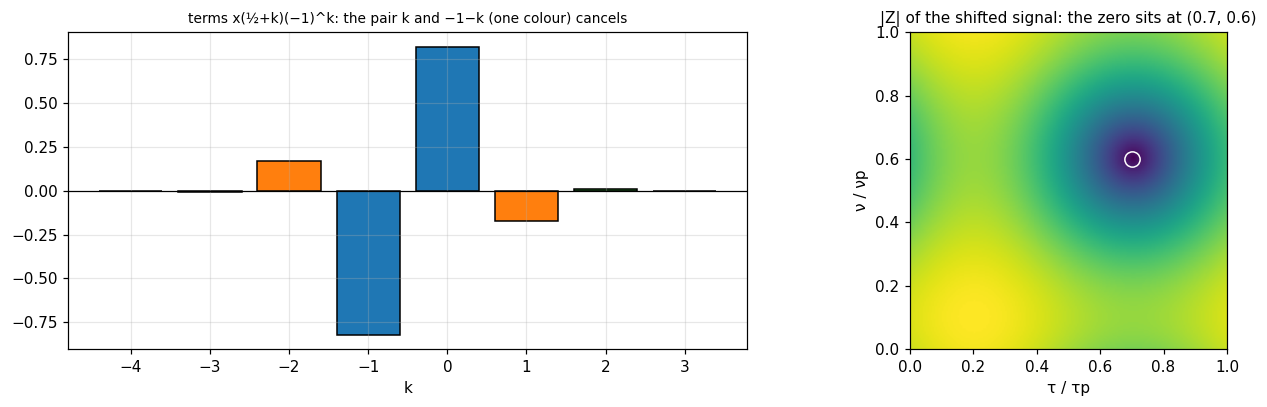

In [9]:
k = np.arange(-4, 4)
g2 = lambda t: gauss(t, 2.0)                                   # wider, so that more terms are visible
terms = g2(0.5 + k) * (-1.0) ** k
print(f"{'k':>3}{'t = ½ + k':>11}{'x(t)':>10}{'(−1)^k':>8}{'term':>12}")
for kk, tm in zip(k, terms): print(f"{kk:>3}{0.5 + kk:>11.1f}{g2(0.5 + kk):>10.5f}{(-1.0) ** kk:>8.0f}{tm:>12.5f}")
print(f"sum = Z(½, ½) = {terms.sum():.2e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
pair = np.where(k >= 0, k, -1 - k)                              # the pair (k, −1−k) shares a colour
ax[0].bar(k, terms, color=[f"C{p}" for p in pair], edgecolor="k")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlabel("k"); ax[0].set_title("terms x(½+k)(−1)^k: the pair k and −1−k (one colour) cancels", fontsize=9)

# a shifted and modulated Gaussian: the zero leaves (½, ½)
a_s, b_s = 0.2, 0.1
xs_ = lambda t: gauss(np.asarray(t) - a_s) * np.exp(2j * np.pi * b_s * np.asarray(t))
tt_ = np.arange(200) / 200; Zs = zak(xs_, tt_, tt_)
i, j = np.unravel_index(np.argmin(np.abs(Zs)), Zs.shape)
res = minimize(lambda p: abs(zak_pairs(xs_, p[0], p[1])[0]) ** 2, [tt_[i], tt_[j]], method="Nelder-Mead", options=dict(xatol=1e-10, fatol=1e-30))
print(f"|Z(½,½)| for the shifted signal = {abs(zak_pairs(xs_, 0.5, 0.5)[0]):.3f}")
print(f"zero found at (τ, ν) = ({res.x[0]:.6f}, {res.x[1]:.6f}),  prediction (½ + a, ½ + b) = ({0.5 + a_s:.6f}, {0.5 + b_s:.6f}),  |Z| = {np.sqrt(res.fun):.1e}")
show_dd(ax[1], Zs, (0, 1, 0, 1), "|Z| of the shifted signal: the zero sits at (0.7, 0.6)")
ax[1].plot(*res.x, "wo", mfc="none", ms=10)
plt.tight_layout(); plt.show()

### 7b. Symmetry + twist: why exactly $(\tfrac12,\tfrac12)$ and not the other points
The reflection $t\mapsto-t$ acts on the plane as $(\tau,\nu)\mapsto(-\tau,-\nu)$: for an even $x$ we get $Z(-\tau,-\nu)=Z(\tau,\nu)$ (substitute $k\to-k$). The fixed points of this reflection *modulo the lattice* are four: $(0,0),\ (\tfrac12,0),\ (0,\tfrac12),\ (\tfrac12,\tfrac12)$. Let us see what quasi-periodicity demands in each. At $(\tfrac12,\tfrac12)$:
$$Z(-\tfrac12,-\tfrac12)\overset{\text{period in }\nu}{=}Z(-\tfrac12,\tfrac12)\overset{\text{twist, }n=-1}{=}e^{-j2\pi\cdot\frac12}Z(\tfrac12,\tfrac12)=-Z(\tfrac12,\tfrac12).$$
Symmetry says the left-hand side equals $+Z(\tfrac12,\tfrac12)$. The only number equal to its own negative is zero. At the other three fixed points the twist $e^{j2\pi n\nu}$ equals $+1$ (there either $\nu=0$ or the shift is $n=0$), there is no contradiction, and the values are non-zero (last printout). **The zero appears exactly where the twist gives $-1$**: this is the "half a turn of phase" contribution from section 3.

In [10]:
P = rng.uniform(-1.5, 1.5, (2000, 2)); tt, nn = P[:, 0], P[:, 1]
e1 = np.max(np.abs(zak_pairs(g, -tt, -nn) - zak_pairs(g, tt, nn)))
print(f"even signal:  max|Z(−τ,−ν) − Z(τ,ν)| = {e1:.1e}")
e2 = np.max(np.abs(zak_pairs(g, tt - 1, nn) - np.exp(-2j * np.pi * nn) * zak_pairs(g, tt, nn)))
print(f"quasi-periodicity:  max|Z(τ−1,ν) − e^(−j2πν)·Z(τ,ν)| = {e2:.1e}")
z = zak_pairs(g, [0.5, -0.5, -0.5], [0.5, 0.5, -0.5])
print("Z(½,½), Z(−½,½), Z(−½,−½) =", np.round(z, 12), "  → the second = −the first (twist e^{−jπ} = −1), the third = the second (period in ν)")

print("\nthe four fixed points of the reflection (τ, ν) → (−τ, −ν) modulo the lattice:")
for p in ((0, 0), (0.5, 0), (0, 0.5), (0.5, 0.5)):
    print(f"  (τ, ν) = {p}:  Z = {zak_pairs(g, p[0], p[1])[0]:+.5f}")

even signal:  max|Z(−τ,−ν) − Z(τ,ν)| = 2.5e-16
quasi-periodicity:  max|Z(τ−1,ν) − e^(−j2πν)·Z(τ,ν)| = 7.9e-16
Z(½,½), Z(−½,½), Z(−½,−½) = [ 0.+0.j -0.-0.j -0.+0.j]   → the second = −the first (twist e^{−jπ} = −1), the third = the second (period in ν)

the four fixed points of the reflection (τ, ν) → (−τ, −ν) modulo the lattice:
  (τ, ν) = (0, 0):  Z = +1.08643+0.00000j
  (τ, ν) = (0.5, 0):  Z = +0.91358+0.00000j
  (τ, ν) = (0, 0.5):  Z = +0.91358+0.00000j
  (τ, ν) = (0.5, 0.5):  Z = +0.00000+0.00000j


### 7c. Topology: the phase must "wind", so there is a vortex somewhere
For an asymmetric signal the previous argument fails, yet a zero still exists. Suppose $Z$ is continuous and **nowhere zero** on $[0,1]^2$. Then it has a continuous phase, and we can measure how much the phase changes around the border of the square. Walk around the border (bottom, right, top, left) and add up the phase increments using quasi-periodicity:
- bottom and top sides: $Z(\tau,1)=Z(\tau,0)$, and we traverse them in opposite directions, so their phase increments cancel;
- right and left sides: $Z(1,\nu)=e^{j2\pi\nu}Z(0,\nu)$. We go down the left side (increment $-\Delta$) and up the right side: $+\Delta$ from $Z(0,\nu)$ itself plus the increment of the factor $e^{j2\pi\nu}$ for $\nu$ from 0 to 1, i.e. $+2\pi$. The intrinsic increments cancel and only the twist remains.

Total: **$+2\pi$, i.e. the phase makes exactly one turn around the border**. But if there are no zeros inside the square, the phase can be continuously contracted to a point, and a turn around a closed contour must be **0**. Contradiction. Hence there is a zero inside, and **the phase winding around it (the index) is $+1$**: the zero is a vortex, near which $Z\approx\alpha\,\delta\tau+\beta\,\delta\nu$ (linear, so $\lvert Z\rvert$ grows like the distance, a "cone"). Nowhere did "nowhere zero" use symmetry, so this holds for any continuous signal.

Numerically: count the turns of the phase around the border of the unit square and around a small circle around the zero, for the Gaussian, the shifted signal and eight random smooth signals. Always $+1$. The rectangle has no zero because the premise fails: its $Z$ is **discontinuous** along the line $\tau=1$, and the "vortex" is smeared over the jump.

Gaussian a=1:  winding = +1.0000   around (½,½), radius 0.1: +1.0000
Gaussian a=0.5: winding = +1.0000


shifted and modulated: winding = +1.0000
random smooth complex signals: 

+1.000  +1.000  +1.000  +1.000  +1.000  +1.000  +1.000  +1.000


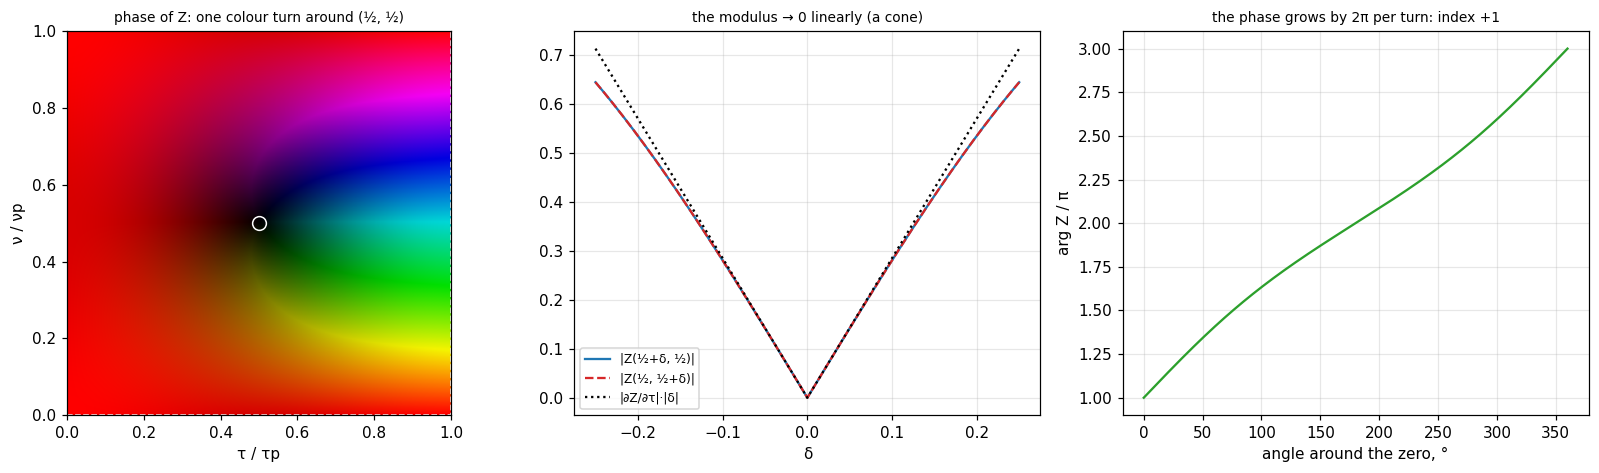

∂Z/∂τ = -2.8487+0.0000j,  ∂Z/∂ν = 0.0000-2.8487j   → near the zero Z ≈ α·δτ + β·δν; here β = jα — a circular vortex


In [11]:
def winding(x, centre=None, radius=None, n=4000):
    """how many turns the phase of Z makes along a contour (counter-clockwise): the unit square [0,1]² or a circle"""
    s = np.linspace(0, 1, n, endpoint=False)
    if centre is None:
        tt = np.concatenate([s, np.ones(n), 1 - s, np.zeros(n)]); nn = np.concatenate([np.zeros(n), s, np.ones(n), 1 - s])
    else:
        ang = 2 * np.pi * np.linspace(0, 1, 4 * n + 1)
        tt = centre[0] + radius * np.cos(ang); nn = centre[1] + radius * np.sin(ang)
    Zp = zak_pairs(x, tt, nn)
    if centre is None: Zp = np.append(Zp, Zp[0])
    return np.sum(np.angle(Zp[1:] / Zp[:-1])) / (2 * np.pi)

print(f"Gaussian a=1:  winding = {winding(g):+.4f}   around (½,½), radius 0.1: {winding(g, (0.5, 0.5), 0.1):+.4f}")
print(f"Gaussian a=0.5: winding = {winding(lambda t: gauss(t, 0.5)):+.4f}")
print(f"shifted and modulated: winding = {winding(xs_):+.4f}")
print("random smooth complex signals:", end=" ")
print("  ".join(f"{winding(random_signal(rng, 4)):+.3f}" for _ in range(8)))

# the picture: the phase and the cross-sections of the modulus through the zero
tau = np.arange(300) / 300; Zg = zak(g, tau, tau)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
show_dd(ax[0], Zg, (0, 1, 0, 1), "phase of Z: one colour turn around (½, ½)", phase=True)
ax[0].plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], "w--", lw=1); ax[0].plot(0.5, 0.5, "wo", mfc="none", ms=9)
ax[0].title.set_fontsize(9)
d = np.linspace(-0.25, 0.25, 201)
cut_t = np.abs(zak(g, 0.5 + d, [0.5])[:, 0]); cut_n = np.abs(zak(g, [0.5], 0.5 + d)[0])
h = 1e-5
dZt = (zak_pairs(g, 0.5 + h, 0.5)[0] - zak_pairs(g, 0.5 - h, 0.5)[0]) / (2 * h)
dZn = (zak_pairs(g, 0.5, 0.5 + h)[0] - zak_pairs(g, 0.5, 0.5 - h)[0]) / (2 * h)
ax[1].plot(d, cut_t, "C0", label="|Z(½+δ, ½)|"); ax[1].plot(d, cut_n, "C3--", label="|Z(½, ½+δ)|")
ax[1].plot(d, np.abs(dZt) * np.abs(d), "k:", label="|∂Z/∂τ|·|δ|")
ax[1].set_xlabel("δ"); ax[1].legend(fontsize=8); ax[1].set_title("the modulus → 0 linearly (a cone)", fontsize=9)
ang = np.linspace(0, 2 * np.pi, 400); r = 0.08
Zc = zak_pairs(g, 0.5 + r * np.cos(ang), 0.5 + r * np.sin(ang))
ax[2].plot(np.degrees(ang), np.unwrap(np.angle(Zc)) / np.pi, "C2"); ax[2].set_xlabel("angle around the zero, °"); ax[2].set_ylabel("arg Z / π")
ax[2].set_title("the phase grows by 2π per turn: index +1", fontsize=9)
plt.tight_layout(); plt.show()
print(f"∂Z/∂τ = {dZt:.4f},  ∂Z/∂ν = {dZn:.4f}   → near the zero Z ≈ α·δτ + β·δν; here β = jα — a circular vortex")

## 8. Consequences: orthogonality, the Gram matrix, Balian–Low
**How Zak acts on a lattice of pulses.** Take a pulse $g$ and its copies $g_{m,n}(t)=g(t-m)\,e^{j2\pi nt}$: shifts by whole periods in delay and whole $\nu_p$ in Doppler. This is exactly the lattice that the Zak-OTFS symbols (pulsones) form. Substituting into the definition (for integer $m,n$ the factor $e^{j2\pi nk}=1$) gives
$$Z_{g_{m,n}}(\tau,\nu)=e^{\,j2\pi(n\tau-m\nu)}\,Z_g(\tau,\nu).$$
A shift and a modulation **turn into multiplication by a harmonic**: $g_{m,n}\mapsto e^{j2\pi(n\tau-m\nu)}Z_g$. And the harmonics $e^{j2\pi(n\tau-m\nu)}$ form an orthonormal basis of $L^2([0,1)^2)$. By unitarity the inner product of copies is
$$\langle g,g_{m,n}\rangle=\iint_{[0,1)^2}\lvert Z_g(\tau,\nu)\rvert^2\,e^{\,j2\pi(n\tau-m\nu)}\,d\tau\,d\nu,$$
that is, **the Gram matrix of the lattice is the set of Fourier coefficients of $\lvert Z_g\rvert^2$**. Three conclusions:
1. the lattice $\{g_{m,n}\}$ is **orthonormal** $\Leftrightarrow$ $\lvert Z_g\rvert^2\equiv1$ (every Fourier coefficient except the zeroth vanishes);
2. the eigenvalues of the Gram operator are the values of $\lvert Z_g\rvert^2$ over the plane; the lattice is a Riesz basis only if $0<\min\lvert Z_g\rvert^2\le\max\lvert Z_g\rvert^2<\infty$;
3. **if $Z_g$ is continuous, then by section 7 it has a zero, $\min\lvert Z_g\rvert=0$, and the lattice cannot even be a Riesz basis**, neither orthonormal nor merely stable. This is the **Balian–Low theorem** in embryo: *a pulse cannot be both well localized in time and in frequency (smooth and fast-decaying) and give an orthonormal lattice of critical density $\tau_p\nu_p=1$*.

Let us check. Printout 1: the rule for $Z_{g_{m,n}}$. Printout 2: the Gram matrix of the Gaussian computed by a time-domain integral and via Fourier coefficients of $\lvert Z\rvert^2$; they agree. The overlap with the four neighbours is $e^{-\pi/2}\approx0.21$.

In [12]:
# the rule: a shift by m and a modulation by n multiply Z by e^{j2π(nτ − mν)}
m_, n_ = 2, -3
gmn = lambda t: gauss(np.asarray(t) - m_) * np.exp(2j * np.pi * n_ * np.asarray(t))
P = rng.uniform(-1, 1, (500, 2)); tt, nn = P[:, 0], P[:, 1]
print(f"max|Z_(m,n)(τ,ν) − e^(j2π(nτ − mν))·Z_g(τ,ν)| = {np.max(np.abs(zak_pairs(gmn, tt, nn) - np.exp(2j * np.pi * (n_ * tt - m_ * nn)) * zak_pairs(g, tt, nn))):.1e}")

# the Gram matrix of lattice neighbours: in time and via Fourier coefficients of |Z|²
dt = 0.002; tg = np.arange(-12, 12, dt)
tau = np.arange(200) / 200; nu = np.arange(200) / 200
W = np.abs(zak(g, tau, nu)) ** 2
Tm, Nm = np.meshgrid(tau, nu, indexing="ij")
E = np.sum(g(tg) ** 2) * dt
G_time = np.zeros((3, 3), complex); G_zak = np.zeros((3, 3), complex)
for i, m in enumerate((-1, 0, 1)):
    for j, n in enumerate((-1, 0, 1)):
        G_time[i, j] = np.sum(g(tg) * g(tg - m) * np.exp(2j * np.pi * n * tg)) * dt / E
        G_zak[i, j] = np.mean(W * np.exp(2j * np.pi * (n * Tm - m * Nm))) / np.mean(W)
np.set_printoptions(precision=4, suppress=True)
print("⟨g, g_(m,n)⟩/‖g‖² in time (rows m = −1,0,1; columns n = −1,0,1):\n", G_time.real)
print("via Fourier coefficients of |Z|²:\n", G_zak.real)
print(f"max|Δ| = {np.max(np.abs(G_time - G_zak)):.1e};   e^(−π/2) = {np.exp(-np.pi / 2):.4f}  — the overlap with the four lattice neighbours")

max|Z_(m,n)(τ,ν) − e^(j2π(nτ − mν))·Z_g(τ,ν)| = 1.2e-14
⟨g, g_(m,n)⟩/‖g‖² in time (rows m = −1,0,1; columns n = −1,0,1):
 [[-0.0432  0.2079 -0.0432]
 [ 0.2079  1.      0.2079]
 [-0.0432  0.2079 -0.0432]]
via Fourier coefficients of |Z|²:
 [[-0.0432  0.2079 -0.0432]
 [ 0.2079  1.      0.2079]
 [-0.0432  0.2079 -0.0432]]
max|Δ| = 2.2e-16;   e^(−π/2) = 0.2079  — the overlap with the four lattice neighbours


The spectrum of the Gram operator for three pulses. The time-domain rectangle and the sinc (a rectangle in frequency) are **ideal**: $\lvert Z\rvert^2\equiv1$, the lattice is orthonormal. But each is poorly localized on one side (the rectangle has spectral tails $\propto1/f$, the sinc has time tails $\propto1/t$), and their $Z$ is discontinuous, so there is no zero, as the theorem demands. The Gaussian is localized on both sides, but its $\lvert Z\rvert^2$ passes through zero: the Gram operator has arbitrarily small eigenvalues, and any receiver that solves a system with this matrix (ZF, LMMSE) amplifies noise exactly along the direction of that zero.

pulse                                           min |Z|²    max |Z|²   = eigenvalues of the Gram matrix
Gaussian                                           0.000       1.669
time rectangle                                     1.000       1.000
sinc (frequency rectangle)                         1.000       1.000


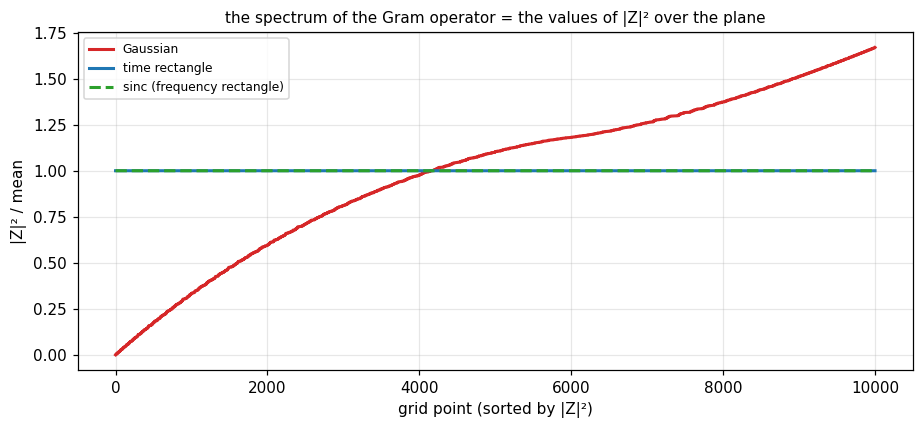

In [13]:
tau = np.arange(100) / 100; nu = np.arange(100) / 100
sinc_X = lambda f: ((f >= -0.5) & (f < 0.5)).astype(float)       # the spectrum of sinc is a rectangle
sets = {"Gaussian": np.abs(zak(g, tau, nu)) ** 2,
        "time rectangle": np.abs(zak(rect, tau, nu)) ** 2,
        "sinc (frequency rectangle)": np.abs(zak_from_spectrum(sinc_X, tau, nu)) ** 2}
fig, ax = plt.subplots(figsize=(8.5, 4))
print(f"{'pulse':<44}{'min |Z|²':>12}{'max |Z|²':>12}   = eigenvalues of the Gram matrix")
for (name, w), c in zip(sets.items(), ("C3", "C0", "C2")):
    w = w / w.mean()
    ax.plot(np.sort(w.ravel()), c, lw=2, ls="--" if "sinc" in name else "-", label=name)
    print(f"{name:<44}{w.min():>12.3f}{w.max():>12.3f}")
ax.set_xlabel("grid point (sorted by |Z|²)"); ax.set_ylabel("|Z|² / mean"); ax.legend(fontsize=8)
ax.set_title("the spectrum of the Gram operator = the values of |Z|² over the plane", fontsize=10)
plt.tight_layout(); plt.show()

**Can the Gaussian be "repaired"?** Yes, at the cost of its tails. Since the Gram matrix is $\lvert Z\rvert^2$, divide $Z$ by $\lvert Z\rvert$: $g_\perp=\mathrm{Zak}^{-1}[\,Z_g/\lvert Z_g\rvert\,]$. The new pulse has $\lvert Z_{g_\perp}\rvert\equiv1$ and the lattice is orthonormal. But $Z_g/\lvert Z_g\rvert$ is **undefined** at the zero (a vortex: the phase takes every value), i.e. discontinuous, and by the inverse Fourier transform in $\nu$ a discontinuity of $Z$ gives a **power-law tail** $\sim1/\lvert t\rvert$ instead of $e^{-\pi t^2}$. The right plot shows the envelopes: $g_\perp$ follows $\approx(0.3\text{–}0.4)/k$ at large $k$, while the original Gaussian drops below $10^{-16}$ already at $k\approx4$. This is Balian–Low in practice: orthogonality is traded for localization.

The practical conclusion for Zak-OTFS: you cannot have everything at once, i.e. orthogonal symbols, a fast-decaying pulse (small out-of-band emission, short channel memory) and critical density $\tau_p\nu_p=1$. Real pulses (Gaussian-sinc, RRC) are a compromise: they allow a shallow dip of $\lvert Z\rvert$ near $(\tfrac12,\tfrac12)$ instead of a zero or a jump. In OFDM the analogous way out is the cyclic prefix, i.e. $\tau_p\nu_p>1$ (a lattice sparser than critical, so the Balian–Low restriction disappears).

‖g⊥‖² = 1.0000  (unit norm: |U| = 1)


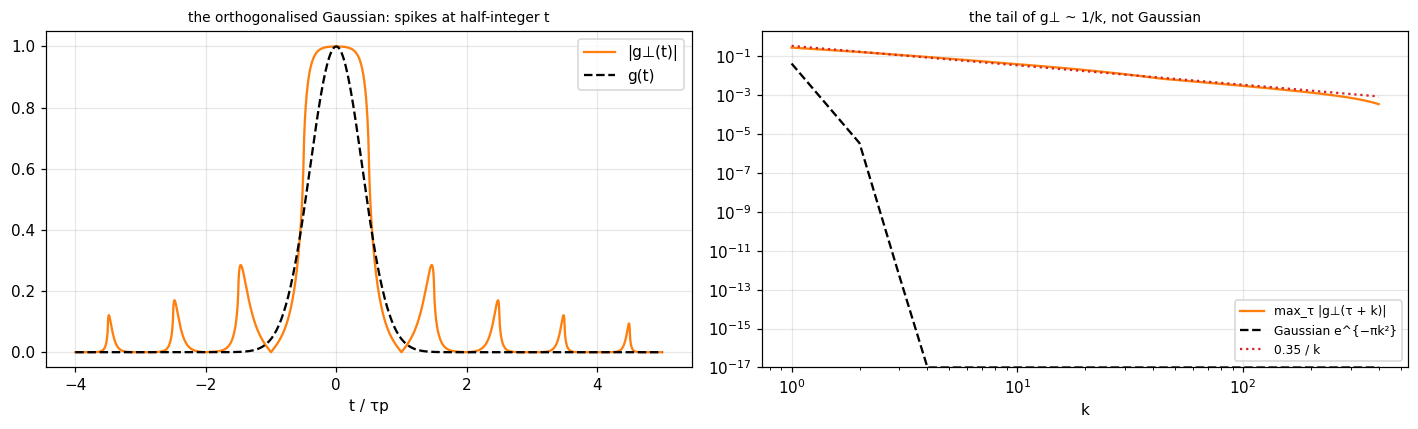

k·max|g⊥|: [0.376 0.394 0.407 0.358 0.312 0.3  ]  → roughly a constant: the tail ∝ 1/k


In [14]:
# orthogonalisation: g⊥ = Zak⁻¹[ Z/|Z| ]
Q, Nn = 256, 1024
tq = np.arange(Q) / Q; nq = np.arange(Nn) / Nn
Zq = zak(g, tq, nq, K=8)
Aq = np.abs(Zq); U = np.where(Aq > 1e-9, Zq / np.maximum(Aq, 1e-300), 0)       # |U| = 1 everywhere except one point
gperp = np.fft.ifft(U, axis=1)                                                  # gperp[iτ, k] = g⊥(τ + k)
print(f"‖g⊥‖² = {np.sum(np.abs(gperp) ** 2) / Q:.4f}  (unit norm: |U| = 1)")
env = np.abs(gperp).max(axis=0)[1:400]
kk = np.arange(1, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tt = (tq[:, None] + np.arange(-4, 5)[None, :])
order = np.argsort(tt.ravel()); gp_t = np.array([gperp[i, k % Nn] for i in range(Q) for k in range(-4, 5)])
ax[0].plot(tt.ravel()[order], np.abs(gp_t)[order], "C1", label="|g⊥(t)|"); ax[0].plot(np.linspace(-4, 5, 500), gauss(np.linspace(-4, 5, 500)), "k--", label="g(t)")
ax[0].set_xlabel("t / τp"); ax[0].legend(); ax[0].set_title("the orthogonalised Gaussian: spikes at half-integer t", fontsize=9)
ax[1].loglog(kk, env, "C1", label="max_τ |g⊥(τ + k)|"); ax[1].loglog(kk, np.exp(-np.pi * kk ** 2) + 1e-17, "k--", label="Gaussian e^{−πk²}")
ax[1].loglog(kk, 0.35 / kk, "C3:", label="0.35 / k")
ax[1].set_ylim(1e-17, 2); ax[1].set_xlabel("k"); ax[1].legend(fontsize=8); ax[1].set_title("the tail of g⊥ ~ 1/k, not Gaussian", fontsize=9)
plt.tight_layout(); plt.show()
print("k·max|g⊥|:", np.round(env[[3, 7, 15, 31, 63, 127]] * kk[[3, 7, 15, 31, 63, 127]], 3), " → roughly a constant: the tail ∝ 1/k")

## 9. The discrete version: why $M$ and $N$ are even
The discrete $Z[k,l]$ from `zak_sim` is a sampling of $Z(\tau,\nu)$ at the points $\tau=k/M$, $\nu=l/N$. The grid contains the point $(\tfrac12,\tfrac12)$, i.e. $k=M/2$, $l=N/2$, **only if $M$ and $N$ are even**. Then the zero shows up in the data exactly, to machine precision ($\sim10^{-17}$), and the strict "pairs cancel" argument works on the samples themselves: $\sum_n(-1)^n\,x[M/2+nM]$ with a symmetric $x$. For odd $M$ or $N$ the grid steps over the zero and the minimum of $\lvert Z\rvert$ is small but not zero. For a real frame it is a related story: the 3–5 dB loss of Gaussian windows relative to rect with the true $H$ (section 5 of `zak_sim`) follows from $\lvert Z\rvert\ne1$, i.e. from the non-orthogonality of Gaussian symbols.

In [15]:
# the discrete version: Z[k, l] is Z(τ, ν) at the points τ = k/M, ν = l/N
def dzt_gauss(M, N, a=1.0, K=30):
    n = np.arange(-K, K + 1)
    k = np.arange(M)
    xs = np.exp(-np.pi * ((k[:, None] + n[None, :] * M) / (a * M)) ** 2)         # samples of g(τ + n), τ = k/M
    return (xs @ np.exp(-2j * np.pi * np.outer(n, np.arange(N) / N))) / np.sqrt(N)  # Z[k, l]

for M_, N_ in ((8, 8), (16, 4), (64, 16), (7, 8), (8, 7), (7, 7)):
    Zd = dzt_gauss(M_, N_)
    kmin, lmin = np.unravel_index(np.argmin(np.abs(Zd)), Zd.shape)
    print(f"M = {M_:>2}, N = {N_:>2}:  min|Z[k,l]| = {np.abs(Zd).min():.2e}  at (k, l) = ({kmin}, {lmin})  → (τ, ν) = ({kmin / M_:.3f}, {lmin / N_:.3f})")

M =  8, N =  8:  min|Z[k,l]| = 2.12e-17  at (k, l) = (4, 4)  → (τ, ν) = (0.500, 0.500)
M = 16, N =  4:  min|Z[k,l]| = 3.00e-17  at (k, l) = (8, 2)  → (τ, ν) = (0.500, 0.500)
M = 64, N = 16:  min|Z[k,l]| = 1.50e-17  at (k, l) = (32, 8)  → (τ, ν) = (0.500, 0.500)
M =  7, N =  8:  min|Z[k,l]| = 7.14e-02  at (k, l) = (3, 4)  → (τ, ν) = (0.429, 0.500)
M =  8, N =  7:  min|Z[k,l]| = 7.63e-02  at (k, l) = (4, 4)  → (τ, ν) = (0.500, 0.571)
M =  7, N =  7:  min|Z[k,l]| = 1.07e-01  at (k, l) = (4, 4)  → (τ, ν) = (0.571, 0.571)


## Summary
| What | Formula / fact | Where checked |
|---|---|---|
| Definition | $Z(\tau,\nu)=\sum_kx(\tau+k)e^{-j2\pi\nu k}$ = reshape + FFT | sections 1–2 |
| Quasi-periodicity | $Z(\tau+n,\nu+m)=e^{j2\pi n\nu}Z(\tau,\nu)$ | section 3 |
| Inverse and Parseval | $x(t)=\int_0^1Z(t,\nu)d\nu$, $\int\lvert x\rvert^2=\iint\lvert Z\rvert^2$ | section 4 |
| Via the spectrum | $Z=e^{j2\pi\nu\tau}\sum_mX(\nu+m)e^{j2\pi m\tau}$ | section 5 |
| Zero of an even pulse | $Z(\tfrac12,\tfrac12)=\sum(-1)^kx(\tfrac12+k)=0$ | sections 7a, 7b |
| Zero of any smooth pulse | phase winding around the cell border $=+1$ $\Rightarrow$ a vortex inside | section 7c |
| Lattice of pulses | Gram = Fourier coefficients of $\lvert Z_g\rvert^2$; orthonormal $\Leftrightarrow\lvert Z_g\rvert\equiv1$ | section 8 |
| Balian–Low | smooth + localized $\Rightarrow$ a zero $\Rightarrow$ no orthonormal lattice at $\tau_p\nu_p=1$ | section 8 |
| Price of orthogonalization | $g_\perp$ has a $\sim1/\lvert t\rvert$ tail | section 8 |

**The short answer to "why a zero at $(\tfrac12,\tfrac12)$":** because a shift by one period multiplies the Zak plane by the phase $e^{j2\pi\nu}$, which equals $-1$ at $\nu=\tfrac12$; a symmetric pulse demands that the value at that point equal its own reflection, while the twist demands that it equal *minus* itself. Only zero is left. For an asymmetric pulse the zero moves but does not disappear, because the phase around the cell border must make one full turn.

## Things to try
- in section 2 replace the Gaussian with `rect` or `sinc_t`: does the zero disappear? (`sinc_t` needs `K` in the hundreds and still converges poorly, which is the $1/t$ tail)
- in section 6 change the Gaussian width $a$ to 0.5 and 2: the zero's position does not move (the pulse is even), the shape of the "cone" around it changes
- in section 7a try an asymmetric pulse such as $x(t)=e^{-\pi t^2}(1+0.5t)$: the zero leaves $(\tfrac12,\tfrac12)$, `winding` is still $+1$
- in section 7c vary the number of terms in `random_signal(rng, n)`: the net index stays $+1$ (extra zeros, if any, come in $+1/-1$ pairs)
- in section 8 replace `g` with `lambda t: gauss(t, 0.5)` or `gauss(t, 2)`: the minimum of $\lvert Z\rvert^2$ is still 0, only the shape of the Gram curve changes
- in section 9 take $M=64$, $N=16$ (as in `zak_sim`) and $M=63$: in the second case the zero hides between the samples